# XGBoost fraud model (Ally)
Features from the EDA:
- **claim % of vehicle value**: fraud rises from ~12% to ~27% as the claim takes a bigger share of the car's value
- **phone / address reuse**: addresses with 7-14 claims have ~55-60% fraud; phones that keep reusing the same few addresses are riskier

Score: `S = sum(investigate * (is_fraud * claim_amount - 2500))`, with at most 2000 claims investigated.

In [1]:
# pip install xgboost scikit-learn   # uncomment if not installed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

INVESTIGATION_COST = 2500
BUDGET_SHARE = 0.2      # 2000 of 10,000 test claims

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("train:", train.shape, " test:", test.shape)
print("fraud rate:", train["is_fraud"].mean())

train: (20000, 11)  test: (10000, 10)
fraud rate: 0.1717


## Feature engineering
Reuse counts are computed over **train + test together**: a phone or address shows up in both files, so counting both gives the real reuse number. This uses only the IDs, never the labels, so nothing leaks.

In [3]:
all_claims = pd.concat([train.drop(columns="is_fraud"), test], ignore_index=True)

phone_count = all_claims["phone_hash"].value_counts()
addr_count = all_claims["address_id"].value_counts()
shop_count = all_claims["repair_shop_id"].value_counts()
phone_n_addr = all_claims.groupby("phone_hash")["address_id"].nunique()   # different addresses per phone
addr_n_phone = all_claims.groupby("address_id")["phone_hash"].nunique()   # different phones per address

shop_cats = sorted(all_claims["repair_shop_id"].unique())
incident_cats = sorted(all_claims["incident_type"].unique())


def make_features(d):
    X = pd.DataFrame(index=d.index)

    # raw numeric columns (XGBoost handles the NaNs itself)
    for c in ["claim_amount", "driver_age", "previous_claim_count", "vehicle_value"]:
        X[c] = d[c]

    # claim as a % of vehicle value
    X["claim_pct"] = d["claim_amount"] / d["vehicle_value"].replace(0, np.nan) * 100
    X["log_claim"] = np.log1p(d["claim_amount"])

    # phone / address reuse
    X["phone_n"] = d["phone_hash"].map(phone_count)
    X["addr_n"] = d["address_id"].map(addr_count)
    X["shop_n"] = d["repair_shop_id"].map(shop_count)
    X["phone_n_addr"] = d["phone_hash"].map(phone_n_addr)
    X["addr_n_phone"] = d["address_id"].map(addr_n_phone)
    X["phone_addr_ratio"] = X["phone_n_addr"] / X["phone_n"]   # low = same phone, same few addresses
    X["addr_phone_ratio"] = X["addr_n_phone"] / X["addr_n"]

    # categoricals
    X["severity"] = d["damage_severity"].str.lower().map({"low": 0, "medium": 1, "high": 2})
    X["incident_type"] = pd.Categorical(d["incident_type"], categories=incident_cats)
    X["repair_shop_id"] = pd.Categorical(d["repair_shop_id"], categories=shop_cats)
    return X


X = make_features(train)
y = train["is_fraud"].to_numpy()
X_test = make_features(test)
amounts = train["claim_amount"].to_numpy()

X.head()

,claim_amount,driver_age,previous_claim_count,vehicle_value,claim_pct,log_claim,phone_n,addr_n,shop_n,phone_n_addr,addr_n_phone,phone_addr_ratio,addr_phone_ratio,severity,incident_type,repair_shop_id
0,254.29,42.0,2,11900.0,2.136891,5.542400,5,4,326,5,4,1.0,1.0,0.0,collision,Sb7a282e399
1,592.05,29.0,0,14600.0,4.055137,6.385279,1,4,217,1,4,1.0,1.0,0.0,collision,S9399315447
2,980.14,58.0,0,17550.0,5.584843,6.888715,3,2,4927,3,2,1.0,1.0,0.0,glass,S1bb582e486
3,729.04,44.0,0,18550.0,3.930135,6.593099,2,3,2470,2,3,1.0,1.0,0.0,collision,S7e56cdce9e
4,16145.05,34.0,0,29300.0,55.102560,9.689431,2,5,4927,2,5,1.0,1.0,NaN,theft,S1bb582e486


## Helper: pick claims and compute the score
Investigate a claim when the expected saving `p(fraud) * claim_amount - 2500` is positive, best first, up to the budget.

In [4]:
def pick_claims(probs, claim_amount, budget):
    expected = probs * claim_amount - INVESTIGATION_COST
    order = np.argsort(-expected)[:budget]
    order = order[expected[order] > 0]
    picked = np.zeros(len(probs), dtype=int)
    picked[order] = 1
    return picked


def score_S(picked, fraud, claim_amount):
    return np.sum(picked * (fraud * claim_amount - INVESTIGATION_COST))

## 5-fold cross-validation

In [5]:
params = dict(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    enable_categorical=True,
    tree_method="hist",
    eval_metric="auc",
    early_stopping_rounds=100,
    random_state=42,
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = np.zeros(len(X))
best_iters = []

for fold, (tr, va) in enumerate(skf.split(X, y), 1):
    model = xgb.XGBClassifier(**params)
    model.fit(X.iloc[tr], y[tr], eval_set=[(X.iloc[va], y[va])], verbose=False)
    oof[va] = model.predict_proba(X.iloc[va])[:, 1]
    best_iters.append(model.best_iteration)
    print(f"fold {fold}: AUC = {roc_auc_score(y[va], oof[va]):.4f}  (best iter {model.best_iteration})")

picked = pick_claims(oof, amounts, budget=int(len(X) * BUDGET_SHARE))
S = score_S(picked, y, amounts)

print("===== CV RESULTS =====")
print(f"OOF ROC-AUC:        {roc_auc_score(y, oof):.4f}")
print(f"Claims investigated: {picked.sum()}")
print(f"Frauds caught:       {(picked * y).sum()} of {y.sum()}")
print(f"S score (20k train): ${S:,.0f}")
print(f"Estimated S for 10k test: ${S / 2:,.0f}")

fold 1: AUC = 0.8282  (best iter 91)
fold 2: AUC = 0.8294  (best iter 138)
fold 3: AUC = 0.8192  (best iter 138)
fold 4: AUC = 0.8242  (best iter 163)
fold 5: AUC = 0.8257  (best iter 122)
===== CV RESULTS =====
OOF ROC-AUC:        0.8246
Claims investigated: 2209
Frauds caught:       995 of 3434
S score (20k train): $12,376,582
Estimated S for 10k test: $6,188,291


## Feature importance

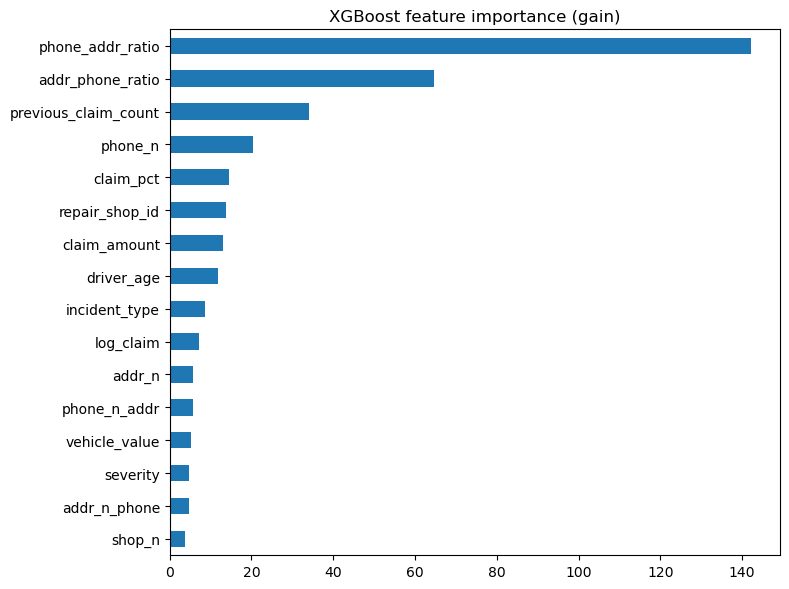

In [6]:
imp = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values()
imp.plot(kind="barh", figsize=(8, 6), title="XGBoost feature importance (gain)")
plt.tight_layout()
plt.show()

## Train on all of train, predict test, write submission

In [7]:
final_params = {**params, "n_estimators": int(np.mean(best_iters) * 1.1)}
final_params.pop("early_stopping_rounds")

final_model = xgb.XGBClassifier(**final_params)
final_model.fit(X, y, verbose=False)

test_probs = final_model.predict_proba(X_test)[:, 1]
investigate = pick_claims(test_probs, test["claim_amount"].to_numpy(), budget=2000)

submission = pd.DataFrame({"claim_id": test["claim_id"], "investigate": investigate})
submission = submission[sample_submission.columns]

assert len(submission) == len(test)
assert submission["claim_id"].is_unique
assert submission["investigate"].isin([0, 1]).all()
assert submission["investigate"].sum() <= 2000

submission.to_csv("submission_xgb.csv", index=False)
print("Claims selected:", submission["investigate"].sum())
submission.head()

Claims selected: 1199


,claim_id,investigate
0,C000003,0
1,C000004,0
2,C000005,0
3,C000006,0
4,C000010,0
